<a href="https://colab.research.google.com/github/HC-AIGroup/CS5330_F26/blob/main/Module%205/Module5_Live_Demos_Recording.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ▶ Module 5 · Live Demos
### CS 5330 · Deep Learning & CNN Foundations
Run the **Setup** cell first.

---
## Setup

In [ ]:
import time, io, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from PIL import Image
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0); np.random.seed(0)
plt.rcParams["figure.dpi"] = 100
print("Running on:", device.upper())

def get_image(fallback="chelsea"):
    """Upload a photo in Colab; if nothing is uploaded, use a built-in sample image."""
    try:
        from google.colab import files
        up = files.upload()
        if up:
            return Image.open(io.BytesIO(next(iter(up.values())))).convert("RGB")
    except Exception as e:
        print("No upload:", e)
    from skimage import data as skdata
    print(f"Using the sample image '{fallback}'.")
    return Image.fromarray(getattr(skdata, fallback)())

Running on: CUDA


---
## ▶ Live demo 1 · What does a pretrained ResNet see?

**What I'll run**
1. Load ResNet-18, trained on 1.2 million ImageNet photos (1,000 classes)
2. Give it four photos it has never seen: a coffee cup, a cat, an astronaut, a rocket
3. One forward pass each: no training at all
4. Show its top-3 guesses for each

> ###  Predict first
> **Which photos will it get right?**
> **What will it say about the astronaut?** (ImageNet has no "person" class.)

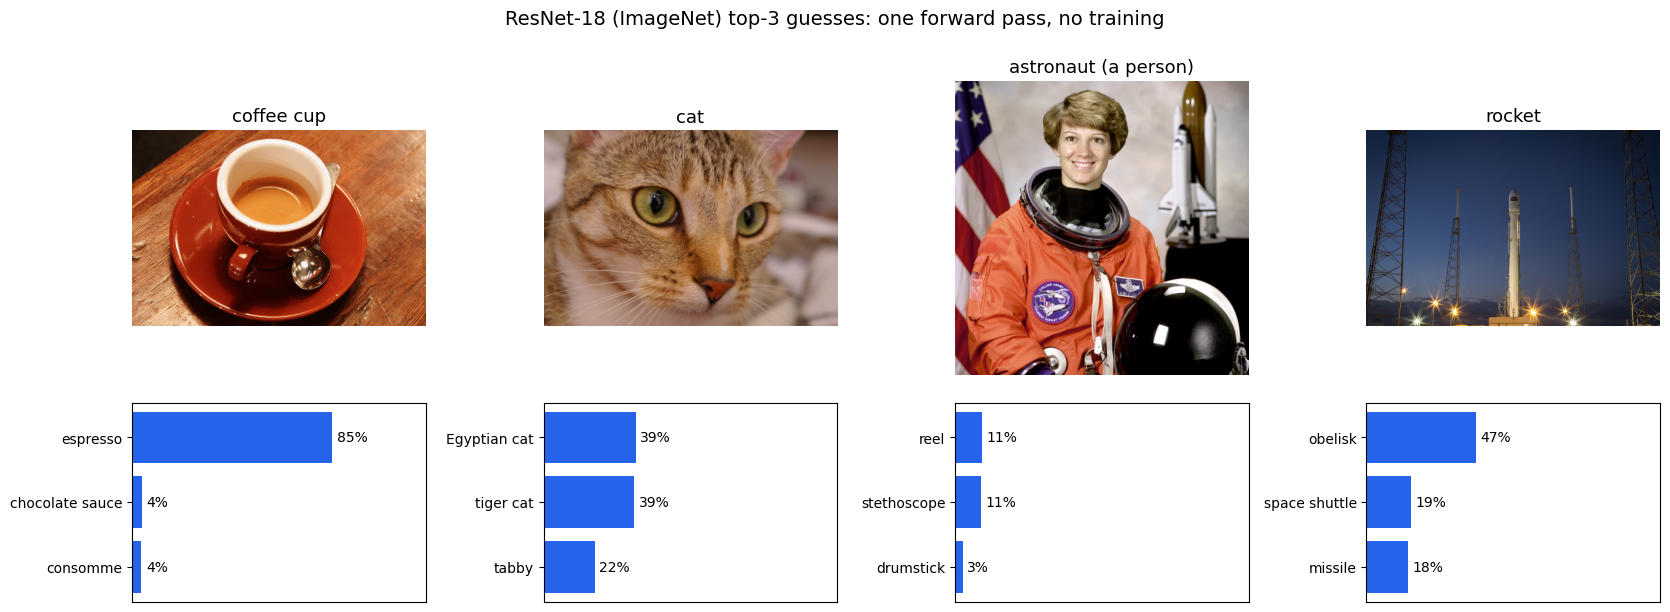

In [ ]:
weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
resnet = torchvision.models.resnet18(weights=weights).to(device).eval()
prep = weights.transforms()                  # resize, crop to 224, ImageNet normalization
CATS = weights.meta["categories"]

from skimage import data as skdata
use_own = False                              # set True to upload your own photo instead
photos = {"coffee cup": skdata.coffee(), "cat": skdata.chelsea(), "astronaut (a person)": skdata.astronaut(), "rocket": skdata.rocket()}
if use_own: photos = {"my photo": np.array(get_image())}

fig, ax = plt.subplots(2, len(photos), figsize=(max(4.2 * len(photos), 6), 6.2), gridspec_kw={"height_ratios": [1.6, 1]}, squeeze=False)
for k, (title, arr) in enumerate(photos.items()):
    img = Image.fromarray(arr).convert("RGB")
    with torch.no_grad():
        p = resnet(prep(img).unsqueeze(0).to(device)).softmax(1)[0].cpu()
    top = p.topk(3)
    ax[0, k].imshow(img); ax[0, k].axis("off"); ax[0, k].set_title(title, fontsize=13)
    names = [CATS[i] for i in top.indices][::-1]; vals = top.values.numpy()[::-1]
    ax[1, k].barh(names, vals, color="#2563EB"); ax[1, k].set_xlim(0, 1.25)
    for y, v in enumerate(vals): ax[1, k].text(v + 0.02, y, f"{v:.0%}", va="center")
    ax[1, k].set_xticks([])
fig.suptitle("ResNet-18 (ImageNet) top-3 guesses: one forward pass, no training", fontsize=14)
plt.tight_layout(); plt.show()

---
## ▶ Live demo 2 · Why skip connections?

**What I'll run**
1. Two 50-layer networks: same layers, same random start
2. Only difference: `h = h + ReLU(layer(h))`, the skip connection
3. Run one backward pass
4. Plot the gradient each layer gets (log scale)

> ###  Predict first
> **In the plain network, how much gradient reaches layer 1, compared with layer 50? And with skips?**

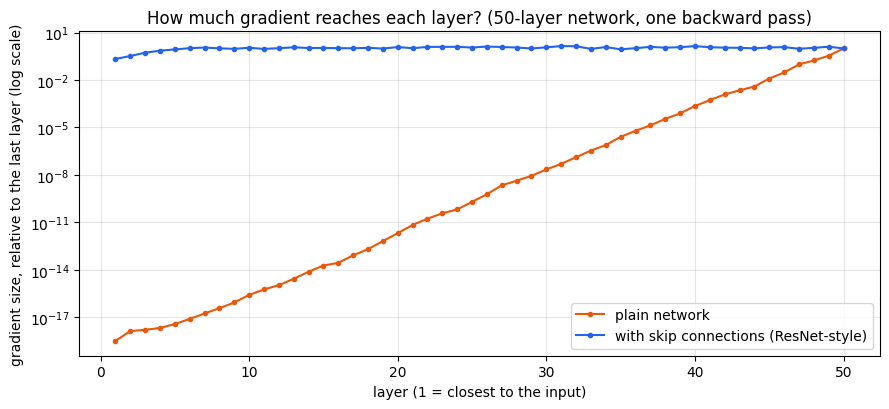

Layer 1 gets 3e-19 of the last layer's gradient (plain) vs. 0.21 (with skips).


In [ ]:
class DeepNet(nn.Module):
    def __init__(self, depth=50, width=64, residual=False):
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(width, width) for _ in range(depth)])
        self.residual = residual
    def forward(self, h):
        for layer in self.layers:
            h = h + F.relu(layer(h)) if self.residual else F.relu(layer(h))
        return h

def gradient_per_layer(residual):
    torch.manual_seed(0)                       # same weights for both networks
    net = DeepNet(residual=residual)
    x = torch.randn(256, 64)
    net(x).mean().backward()                   # one backward pass
    g = torch.tensor([l.weight.grad.abs().mean().item() for l in net.layers])
    return (g / g[-1]).numpy()                 # relative to the last layer

plain, resid = gradient_per_layer(False), gradient_per_layer(True)
plt.figure(figsize=(9, 4.2))
plt.semilogy(range(1, 51), plain, "o-", ms=3, color="#EA580C", label="plain network")
plt.semilogy(range(1, 51), resid, "o-", ms=3, color="#2563EB", label="with skip connections (ResNet-style)")
plt.xlabel("layer (1 = closest to the input)"); plt.ylabel("gradient size, relative to the last layer (log scale)")
plt.title("How much gradient reaches each layer? (50-layer network, one backward pass)")
plt.legend(); plt.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()
print(f"Layer 1 gets {plain[0]:.0e} of the last layer's gradient (plain) vs. {resid[0]:.2f} (with skips).")

---
## ▶ Live demo 3 · Transfer learning in 60 seconds

**What I'll run**
1. Only **30 training images**: 10 airplanes, 10 cars, 10 ships (CIFAR-10)
2. **A:** a small CNN trained from scratch
3. **B:** a frozen ImageNet ResNet-18 + a new linear head
4. Test both on 300 new images

> ### Predict first
> **Guess the test accuracy of A and of B.** Random guessing gives 33%.

training images: 30  test images: 300


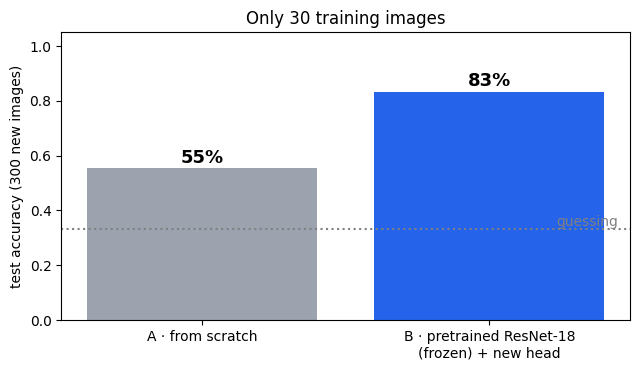

Done in 3 s


In [ ]:
NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
CLS = ["airplane", "automobile", "ship"]
tr = torchvision.datasets.CIFAR10("data", train=True, download=True)
te = torchvision.datasets.CIFAR10("data", train=False, download=True)
def take(ds, per_class):
    y = np.array(ds.targets); X, Y = [], []
    for new, c in enumerate(CLS):
        idx = np.where(y == NAMES.index(c))[0][:per_class]; X.append(ds.data[idx]); Y += [new] * len(idx)
    return np.concatenate(X), np.array(Y)
Xtr, ytr = take(tr, 10)      # 30 training images
Xte, yte = take(te, 100)     # 300 test images
print("training images:", len(Xtr), " test images:", len(Xte))

# ---- A: small CNN from scratch (32 x 32 images, with flips as augmentation)
def to_t(X): return (torch.tensor(X, dtype=torch.float32).permute(0, 3, 1, 2) / 255 - 0.5) / 0.25
small = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                      nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                      nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                      nn.Flatten(), nn.Linear(64 * 4 * 4, 3)).to(device)
xa, ya, xt = to_t(Xtr).to(device), torch.tensor(ytr).to(device), to_t(Xte).to(device)
opt = torch.optim.Adam(small.parameters(), lr=1e-3)
t0 = time.time()
for step in range(300):
    xb = torch.where(torch.rand(len(xa), 1, 1, 1, device=device) < 0.5, xa.flip(3), xa)
    opt.zero_grad(); F.cross_entropy(small(xb), ya).backward(); opt.step()
small.eval()
with torch.no_grad(): acc_A = (small(xt).argmax(1).cpu().numpy() == yte).mean()

# ---- B: frozen pretrained ResNet-18 as a feature extractor + a linear head
backbone = torchvision.models.resnet18(weights=weights).to(device).eval(); backbone.fc = nn.Identity()
@torch.no_grad()
def feats(X):
    return torch.cat([backbone(prep(Image.fromarray(im)).unsqueeze(0).to(device)) for im in X]).cpu().numpy()
from sklearn.linear_model import LogisticRegression
head = LogisticRegression(max_iter=2000).fit(feats(Xtr), ytr)
acc_B = (head.predict(feats(Xte)) == yte).mean()

plt.figure(figsize=(6.5, 3.8))
bars = plt.bar(["A · from scratch", "B · pretrained ResNet-18\n(frozen) + new head"], [acc_A, acc_B], color=["#9CA3AF", "#2563EB"])
plt.axhline(1 / 3, ls=":", color="gray"); plt.text(1.45, 1 / 3 + 0.01, "guessing", color="gray", ha="right")
for b, v in zip(bars, [acc_A, acc_B]): plt.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.0%}", ha="center", fontsize=13, weight="bold")
plt.ylim(0, 1.05); plt.ylabel("test accuracy (300 new images)"); plt.title("Only 30 training images"); plt.tight_layout(); plt.show()
print(f"Done in {time.time() - t0:.0f} s")

---
## ▶ Live demo 4 · YOLO: candidates, confidence & NMS

**What I'll run**
1. Load YOLOv8n, pretrained on COCO (80 classes)
2. Count the raw candidate boxes, before any clean-up
3. Slide the confidence threshold
4. Slide the NMS IoU threshold

> ### Predict first
> **How many candidate boxes for one 640 × 640 image?** (YOLOv3 at 416 × 416 had 10,647.)

In [ ]:
!pip -q install ultralytics
from ultralytics import YOLO
from ultralytics.utils import ASSETS
yolo = YOLO("yolov8n.pt")                    # small model, about 3 million weights

photo = "bus.jpg"                            # built-in street photo; or "zidane.jpg" (two people close together)
use_own = False                              # set True to upload your own street photo instead
scene = get_image() if use_own else Image.open(ASSETS / photo).convert("RGB")

yolo.model.eval()
with torch.no_grad():
    raw = yolo.model(torch.zeros(1, 3, 640, 640).to(next(yolo.model.parameters()).device))
raw = raw[0] if isinstance(raw, (list, tuple)) else raw
print(f"Raw output: {tuple(raw.shape)} → {raw.shape[2]:,} candidate boxes, each with {raw.shape[1]} numbers (4 box + 80 classes)")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Raw output: (1, 84, 8400) → 8,400 candidate boxes, each with 84 numbers (4 box + 80 classes)


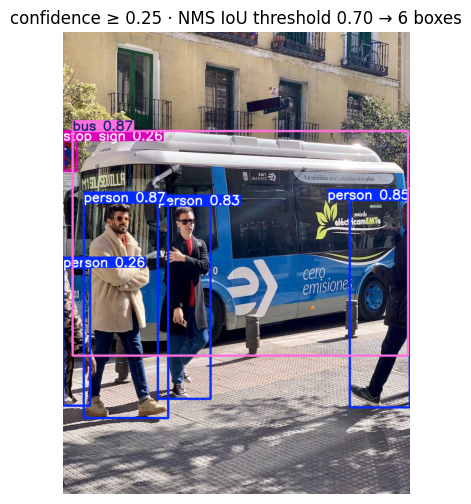

In [ ]:
import ipywidgets as widgets
def detect(conf=0.25, iou=0.7):
    r = yolo(scene, conf=conf, iou=iou, verbose=False)[0]
    plt.figure(figsize=(8, 6)); plt.imshow(r.plot()[..., ::-1]); plt.axis("off")
    plt.title(f"confidence ≥ {conf:.2f} · NMS IoU threshold {iou:.2f} → {len(r.boxes)} boxes"); plt.show()

widgets.interact(detect,
                 conf=widgets.FloatSlider(value=0.25, min=0.01, max=0.95, step=0.01, description="confidence"),
                 iou=widgets.FloatSlider(value=0.70, min=0.05, max=0.95, step=0.05, description="NMS IoU"));

*If the sliders don't appear (for example in a downloaded copy), run these instead:*

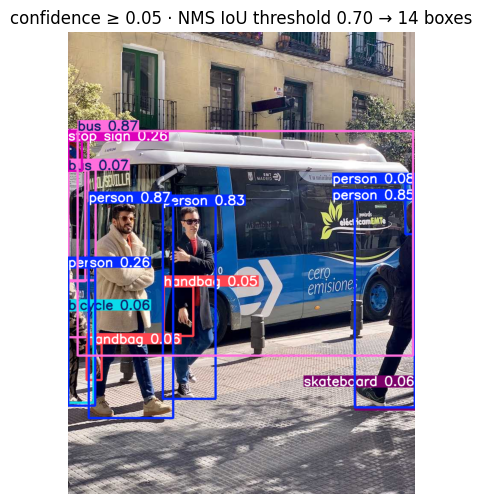

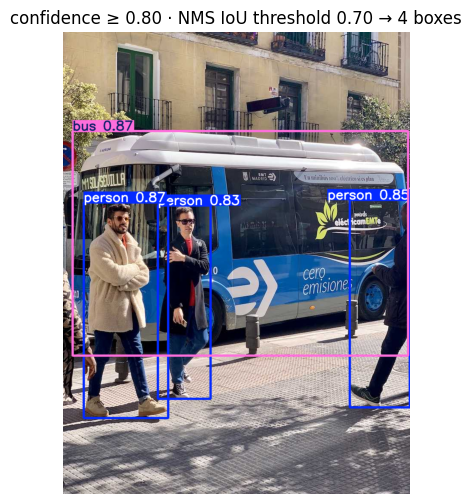

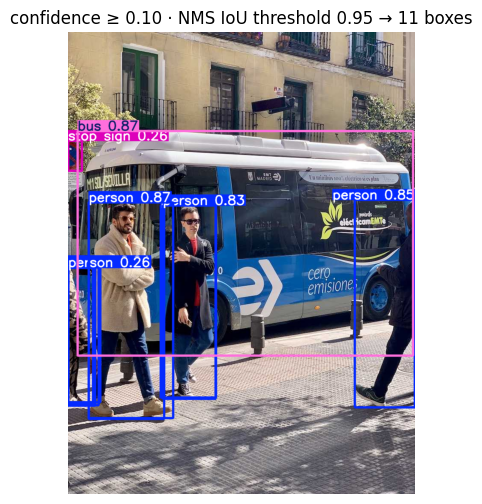

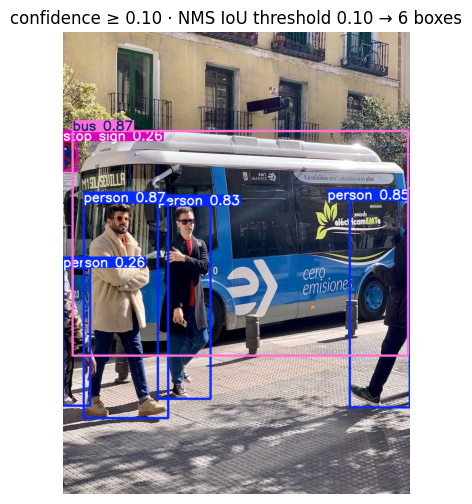

In [ ]:
detect(conf=0.05); detect(conf=0.80)          # knob 1: confidence
detect(conf=0.10, iou=0.95); detect(conf=0.10, iou=0.10)   # knob 2: NMS threshold